In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Import tools for building the preprocessing pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [6]:
ld = pd.read_csv('credit_risk_dataset.csv')

##Initial Data Inspection

In [3]:
ld.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [7]:
ld.shape

(32581, 12)

In [8]:
ld.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


In [9]:
ld.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [10]:
ld.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

##Data Quality Assessment

In [11]:
ld['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

In [12]:
ld['loan_status'].value_counts(normalize=True) * 100

loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64

In [13]:
ld.duplicated().sum()

np.int64(165)

In [14]:
ld.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [15]:
ld['person_age'].sort_values(ascending=False).head(10)

81       144
183      144
32297    144
575      123
747      123
32416     94
32506     84
32422     80
32355     78
32534     76
Name: person_age, dtype: int64

In [16]:
ld['person_emp_length'].sort_values(ascending=False).head(10)

210      123.0
0        123.0
32355     41.0
32515     38.0
32428     34.0
31866     31.0
30914     31.0
31867     31.0
32263     31.0
32539     30.0
Name: person_emp_length, dtype: float64

**Observation:** The dataset contains unusual values in `person_age` and `person_emp_length`. Some ages and employment durations are unrealistically high, suggesting possible data-quality issues that require further investigation before cleaning.

In [20]:
# Count records with unusually high age and employment length

print("Age above 100:", (ld['person_age'] > 100).sum())
print("Employment length above 50:", (ld['person_emp_length'] > 50).sum())

Age above 100: 5
Employment length above 50: 2


**Observation:** Five records have ages above 100, while two records have employment lengths exceeding 50 years. These values appear unrealistic and will require attention during data cleaning.

In [21]:
# Check unique categories in categorical columns

categorical_cols = ld.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}")
    print(ld[col].value_counts())


person_home_ownership
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

cb_person_default_on_file
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_15896\3235498415.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = ld.select_dtypes(include='object').columns


**Observation:** The categorical variables contain four distinct groups of borrower and loan characteristics. RENT is the most common home ownership status, EDUCATION is the most common loan purpose, Grade A is the most frequent loan grade, and most borrowers have no previous default recorded.

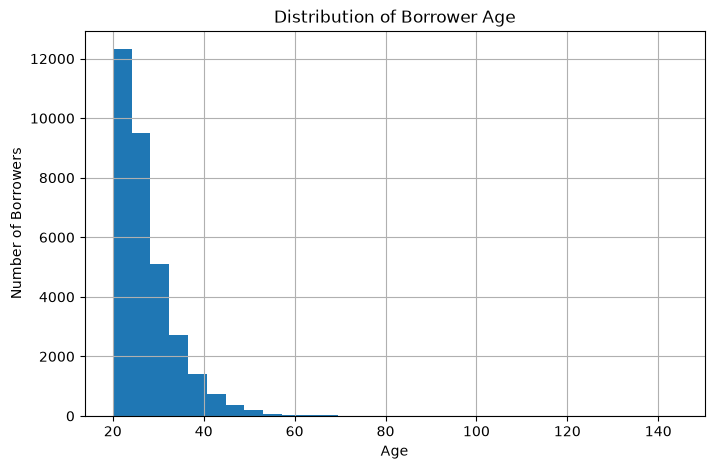

In [22]:
# Examine the distribution of borrowers' ages
ld['person_age'].hist(bins=30, figsize=(8, 5))
plt.title('Distribution of Borrower Age')
plt.xlabel('Age')
plt.ylabel('Number of Borrowers')
plt.show()

**Observation:** Most borrowers are young adults, with the highest concentration between 20 and 30 years. The age distribution is right-skewed, with relatively few older borrowers. A few unusually high age values extend the distribution's upper range and may require treatment during data cleaning.

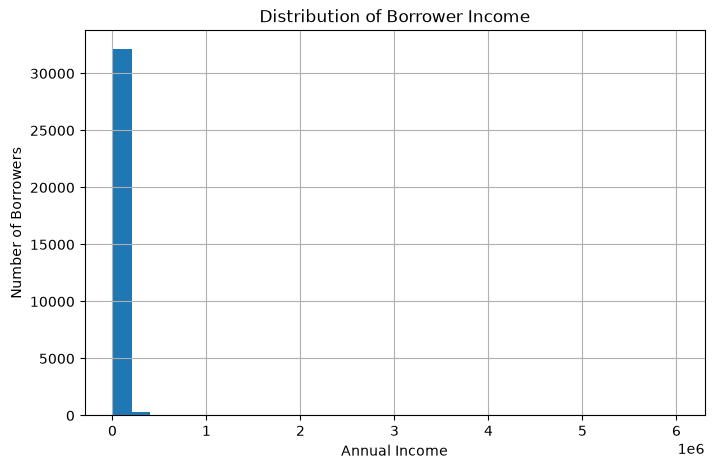

In [23]:
# Examine the distribution of borrowers' income
ld['person_income'].hist(bins=30, figsize=(8, 5))

plt.title('Distribution of Borrower Income')
plt.xlabel('Annual Income')
plt.ylabel('Number of Borrowers')
plt.show()

**Observation:** Borrower income is strongly right-skewed, with most observations concentrated at the lower end of the distribution. A small number of borrowers have significantly higher incomes, suggesting the presence of potential outliers that will be investigated during data cleaning.

In [24]:
# Examine employment length statistics
ld['person_emp_length'].describe()

count    31686.000000
mean         4.789686
std          4.142630
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max        123.000000
Name: person_emp_length, dtype: float64

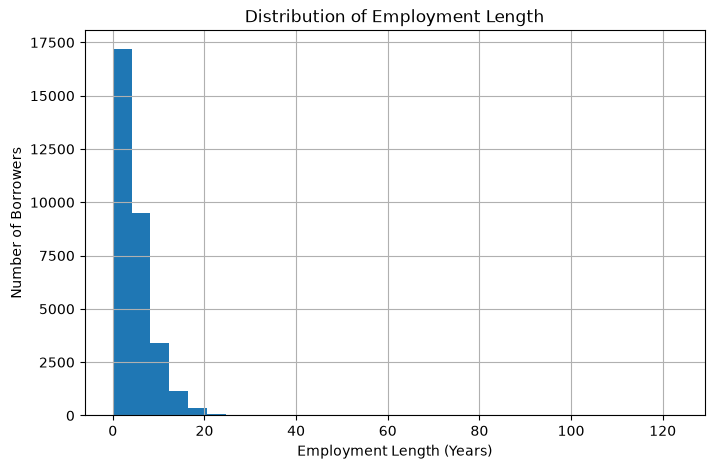

In [25]:
# Examine the distribution of borrowers' employment length
ld['person_emp_length'].hist(bins=30, figsize=(8, 5))

plt.title('Distribution of Employment Length')
plt.xlabel('Employment Length (Years)')
plt.ylabel('Number of Borrowers')
plt.show()

**Observation:** Borrowers have an average employment length of approximately 4.79 years, with a median of 4 years. Most borrowers have between 2 and 7 years of employment history. However, the maximum value of 123 years is unrealistic and requires further investigation.

In [13]:
# Examine loan amount statistics
ld['loan_amnt'].describe()

count    32581.000000
mean      9589.371106
std       6322.086646
min        500.000000
25%       5000.000000
50%       8000.000000
75%      12200.000000
max      35000.000000
Name: loan_amnt, dtype: float64

**Observation:** The average loan amount is approximately 9,589, while the median is 8,000. Most borrowers requested between 5,000 and 12,200. The maximum loan amount is 35,000, indicating a relatively wide range of loan requests.

In [14]:
# Examine loan interest rate statistics
ld['loan_int_rate'].describe()

count    29465.000000
mean        11.011695
std          3.240459
min          5.420000
25%          7.900000
50%         10.990000
75%         13.470000
max         23.220000
Name: loan_int_rate, dtype: float64

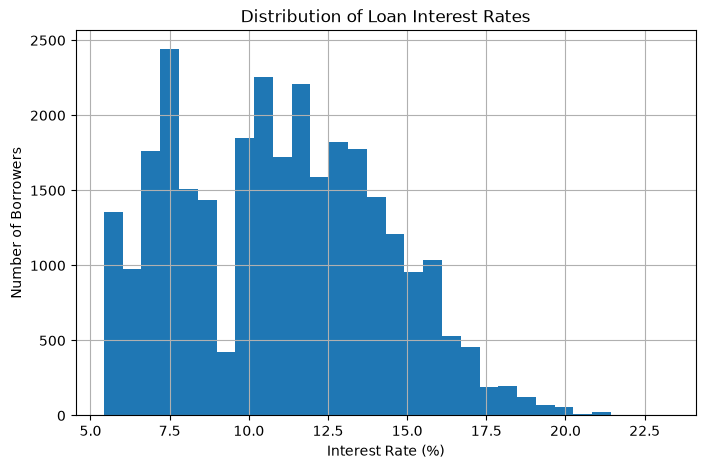

In [15]:
# Visualise the distribution of loan interest rates
ld['loan_int_rate'].hist(bins=30, figsize=(8, 5))

plt.title('Distribution of Loan Interest Rates')
plt.xlabel('Interest Rate (%)')
plt.ylabel('Number of Borrowers')
plt.show()

**Observation:** Most borrowers have interest rates between 7% and 14%. The distribution shows noticeable concentrations around certain interest-rate ranges and a tail extending towards higher rates. A relatively small number of borrowers have rates above 17%.

In [16]:
# Examine borrowers' credit history length
ld['cb_person_cred_hist_length'].describe()

count    32581.000000
mean         5.804211
std          4.055001
min          2.000000
25%          3.000000
50%          4.000000
75%          8.000000
max         30.000000
Name: cb_person_cred_hist_length, dtype: float64

Borrowers have an average credit history length of approximately 5.8 years, with a median of 4 years. Most borrowers have between 3 and 8 years of credit history. The maximum recorded length is 30 years, which does not immediately appear unrealistic.

##Exploratory Data Analysis (EDA)

In [17]:
# Examine default rates across loan grades
ld.groupby('loan_grade')['loan_status'].mean() * 100

loan_grade
A     9.956389
B    16.275954
C    20.733973
D    59.045780
E    64.419087
F    70.539419
G    98.437500
Name: loan_status, dtype: float64

Default rates generally increase as loan grades decline. Grade A has the lowest default rate (9.96%), while Grade G has the highest (98.44%). This suggests a strong relationship between loan grade and default risk, although grades with fewer borrowers should be interpreted cautiously.

In [18]:
# Examine default rates across home ownership categories
ld.groupby('person_home_ownership')['loan_status'].mean() * 100

person_home_ownership
MORTGAGE    12.570663
OTHER       30.841121
OWN          7.469040
RENT        31.569987
Name: loan_status, dtype: float64

Default rates vary considerably across home ownership categories. Borrowers who own their homes have the lowest default rate (7.47%), while renters have the highest (31.57%). This suggests that home ownership status may be associated with default risk. The OTHER category also has a high default rate but should be interpreted cautiously due to its small representation.

In [19]:
# Examine default rates across loan purposes
ld.groupby('loan_intent')['loan_status'].mean() * 100

loan_intent
DEBTCONSOLIDATION    28.587874
EDUCATION            17.216798
HOMEIMPROVEMENT      26.102635
MEDICAL              26.700708
PERSONAL             19.887702
VENTURE              14.810282
Name: loan_status, dtype: float64

Default rates vary across loan purposes. Debt consolidation has the highest default rate (28.59%), followed by medical (26.70%) and home improvement loans (26.10%). Venture loans have the lowest default rate (14.81%). This suggests that loan purpose may be associated with borrowers' likelihood of default.

In [20]:
# Examine default rates based on previous default history
ld.groupby('cb_person_default_on_file')['loan_status'].mean() * 100

cb_person_default_on_file
N    18.393203
Y    37.806789
Name: loan_status, dtype: float64

Borrowers with a previous default history have a considerably higher current default rate (37.81%) compared to those without previous defaults (18.39%). This suggests that previous default history may be an important indicator of future credit risk.

In [21]:
# Examine default rates across employment lengths
ld.groupby('person_emp_length')['loan_status'].mean() * 100

person_emp_length
0.0       27.941535
1.0       27.650086
2.0       25.643024
3.0       20.138889
4.0       21.224774
5.0       18.601494
6.0       18.754689
7.0       18.761384
8.0       16.656787
9.0       17.849305
10.0      17.097701
11.0      18.378378
12.0      15.652174
13.0      11.971831
14.0      16.716418
15.0      18.067227
16.0      12.121212
17.0      17.054264
18.0      10.576923
19.0      14.062500
20.0      30.952381
21.0      26.315789
22.0      15.789474
23.0      30.000000
24.0      30.000000
25.0       0.000000
26.0      16.666667
27.0      20.000000
28.0       0.000000
29.0     100.000000
30.0      50.000000
31.0       0.000000
34.0     100.000000
38.0       0.000000
41.0       0.000000
123.0     50.000000
Name: loan_status, dtype: float64

Default rates generally tend to be higher among borrowers with shorter employment histories and decline as employment length increases. However, the pattern is not consistent across all categories. Some unusually high or low default rates among borrowers with longer employment histories may be influenced by small group sizes and require further investigation.

In [22]:
ld.groupby('person_emp_length')['loan_status'].agg(['count', 'mean'])

,count,mean
person_emp_length,,
0.0,4105,0.279415
1.0,2915,0.276501
2.0,3849,0.256430
3.0,3456,0.201389
4.0,2874,0.212248
5.0,2946,0.186015
6.0,2666,0.187547
7.0,2196,0.187614
8.0,1687,0.166568


The number of borrowers decreases considerably as employment length increases. The higher default rates observed in some longer employment categories are based on very small groups and may not be representative. The more populated categories suggest that borrowers with shorter employment histories generally have higher default rates.

In [23]:
# Compare average interest rates for defaulters and non-defaulters
ld.groupby('loan_status')['loan_int_rate'].mean()

loan_status
0    10.435999
1    13.060207
Name: loan_int_rate, dtype: float64

Borrowers who defaulted had a higher average interest rate (13.06%) compared to non-defaulters (10.44%). This suggests a possible relationship between higher interest rates and loan default risk.

In [24]:
# Compare average loan-to-income ratios by default status
ld.groupby('loan_status')['loan_percent_income'].mean()

loan_status
0    0.148805
1    0.246889
Name: loan_percent_income, dtype: float64

Borrowers who defaulted had a higher average loan-to-income ratio (24.69%) compared to non-defaulters (14.88%). This suggests that borrowers with larger loan obligations relative to their income may face a higher risk of default.

In [25]:
# Compare average loan amounts by default status
ld.groupby('loan_status')['loan_amnt'].mean()

loan_status
0     9237.464178
1    10850.502954
Name: loan_amnt, dtype: float64

Borrowers who defaulted had a higher average loan amount (10,850.50) compared to non-defaulters (9,237.46). This suggests that larger loan amounts may be associated with a higher risk of default.

In [26]:
# Compare average borrower income by default status
ld.groupby('loan_status')['person_income'].mean()

loan_status
0    70804.361559
1    49125.652223
Name: person_income, dtype: float64

Borrowers who defaulted had a lower average annual income (49,125.65) compared to non-defaulters (70,804.36). This suggests that lower income may be associated with a higher risk of loan default.

In [27]:
# Compare average credit history length by default status
ld.groupby('loan_status')['cb_person_cred_hist_length'].mean()

loan_status
0    5.837475
1    5.685003
Name: cb_person_cred_hist_length, dtype: float64

The average credit history length is relatively similar for defaulters (5.69 years) and non-defaulters (5.84 years). This suggests that credit history length alone may have a limited relationship with loan default status.

In [28]:
# Compare average borrower age by default status
ld.groupby('loan_status')['person_age'].mean()

loan_status
0    27.807129
1    27.474676
Name: person_age, dtype: float64

The average age of defaulters (27.47 years) is slightly lower than that of non-defaulters (27.81 years). However, the difference is small, suggesting that age alone may have a limited relationship with loan default status.

In [29]:
# Compare missing employment length across default status
ld.groupby('loan_status')['person_emp_length'].apply(lambda x: x.isna().mean() * 100)

loan_status
0    2.406470
1    3.967361
Name: person_emp_length, dtype: float64

Missing employment-length information is more common among defaulters (3.97%) than non-defaulters (2.41%). This difference suggests that missingness may be associated with default status and should be considered when selecting an appropriate imputation method.

In [30]:
# Compare missing interest rate values across default status
ld.groupby('loan_status')['loan_int_rate'].apply(lambda x: x.isna().mean() * 100)

loan_status
0    9.704393
1    9.060214
Name: loan_int_rate, dtype: float64

Missing interest rate values occur at relatively similar rates among non-defaulters (9.70%) and defaulters (9.06%). This suggests that missingness in this variable is not strongly associated with default status.

## 7. Data Cleaning and Preparation

In [31]:
# Check the number of duplicate records
ld.duplicated().sum()

np.int64(165)

In [32]:
# Remove duplicate records
ld = ld.drop_duplicates()

In [33]:
# Confirm that duplicate records have been removed
ld.duplicated().sum()

np.int64(0)

A total of 165 duplicate records were identified and removed from the dataset. This ensures that repeated records do not unnecessarily influence subsequent analysis and model development.

## 7.2 Handling Unusual Values

In [34]:
# Identify borrowers with unusually high ages
ld[ld['person_age'] > 100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


In [35]:
# Count borrowers with ages above 100
(ld['person_age'] > 100).sum()

np.int64(5)

In [36]:
# Remove records with unrealistic borrower ages
ld = ld[ld['person_age'] <= 100]

In [37]:
# Confirm that no borrower is above 100 years old
(ld['person_age'] > 100).sum()

np.int64(0)

Five records with ages above 100 years were identified as unrealistic and removed from the dataset. These values were treated as invalid observations rather than replaced with estimated ages.

In [38]:
# Identify unusually high employment lengths
ld[ld['person_emp_length'] > 50]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


In [39]:
# Replace unrealistic employment lengths with missing values
ld.loc[ld['person_emp_length'] > 50, 'person_emp_length'] = np.nan

In [40]:
# Check the maximum employment length
ld['person_emp_length'].max()

np.float64(41.0)

Two records with employment lengths of 123 years were identified as invalid and replaced with missing values. The remaining records were retained to preserve other useful borrower information.

In [41]:
# Examine the 10 highest borrower incomes
ld.nlargest(10, 'person_income')

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
30049,42,2039784,RENT,0.0,VENTURE,C,8450,12.29,0,0.00,Y,15
32546,60,1900000,MORTGAGE,5.0,PERSONAL,A,1500,NaN,0,0.00,N,21
32497,63,1782000,RENT,13.0,EDUCATION,C,12025,14.27,0,0.01,N,30
31924,44,1440000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,6400,7.40,0,0.00,N,15
31922,47,1362000,MORTGAGE,9.0,VENTURE,A,6600,7.74,0,0.00,N,17
17833,32,1200000,MORTGAGE,1.0,VENTURE,A,12000,7.51,0,0.01,N,8
29119,36,1200000,OWN,16.0,MEDICAL,A,10000,6.54,0,0.01,N,11
29120,40,1200000,MORTGAGE,1.0,MEDICAL,A,10000,NaN,0,0.01,N,16
17834,34,948000,MORTGAGE,18.0,PERSONAL,B,2000,9.99,0,0.00,N,7
29121,50,900000,MORTGAGE,11.0,DEBTCONSOLIDATION,B,30000,12.69,0,0.03,N,15


The income distribution contains some extremely high values, with the maximum exceeding 2 million. However, the associated borrower characteristics do not immediately suggest invalid records. These observations will be retained for now and considered during further analysis and model development.

In [42]:
# Examine income distribution at selected percentiles
ld['person_income'].quantile([0.90, 0.95, 0.99, 0.995, 1.00])

0.900     110004.0
0.950     138000.0
0.990     225000.0
0.995     300000.0
1.000    2039784.0
Name: person_income, dtype: float64

The income percentiles reveal a highly concentrated distribution, with 99% of borrowers earning 225,000 or less. However, the maximum income is approximately 2,039,784, indicating the presence of extreme high-income outliers. These observations will be retained for further investigation and considered during model development.

In [43]:
# Count borrowers with income above 300,000
(ld['person_income'] > 300000).sum()

np.int64(136)

Only 136 borrowers (approximately 0.42% of the dataset) have incomes above 300,000. Although these values are extreme, they will be retained for now because unusually high income does not necessarily indicate inaccurate data.

In [44]:
ld['loan_amnt'].quantile([0.90, 0.95, 0.99, 1.00])

0.90    19000.0
0.95    24000.0
0.99    29800.0
1.00    35000.0
Name: loan_amnt, dtype: float64

Loan amounts range from 500 to 35,000. Although some borrowers requested relatively large loans, the maximum value does not appear excessively far from the 99th percentile. No records were removed based on loan amount.

In [45]:
ld['loan_percent_income'].quantile([0.90, 0.95, 0.99, 1.00])

0.90    0.32
0.95    0.38
0.99    0.50
1.00    0.83
Name: loan_percent_income, dtype: float64

The loan-to-income ratio is generally concentrated below 50%, with 99% of borrowers having a ratio of 0.50 or less. However, the maximum value of 0.83 indicates that some borrowers have relatively high loan amounts compared to their income. These observations will be retained because they may represent genuine high-risk cases.

In [46]:
(ld['loan_percent_income'] > 0.60).sum()

np.int64(50)

Only 50 borrowers (approximately 0.15% of the dataset) have loan-to-income ratios above 0.60. These observations were retained because they may represent genuine high-risk borrowers rather than incorrect records.

In [47]:
#check the interest rate for unusual values
ld['loan_int_rate'].quantile([0.01, 0.05, 0.95, 0.99, 1.00])

0.01     5.42
0.05     6.03
0.95    16.32
0.99    18.62
1.00    23.22
Name: loan_int_rate, dtype: float64

Interest rates range from 5.42% to 23.22%. Although a few borrowers have relatively high interest rates, these values may reflect differences in credit risk rather than data entry errors. No records were removed based on interest rate.

In [48]:
# Check the distribution of borrowers' credit history lengths
ld['cb_person_cred_hist_length'].quantile([0.01, 0.05, 0.95, 0.99, 1.00])

0.01     2.0
0.05     2.0
0.95    14.0
0.99    17.0
1.00    30.0
Name: cb_person_cred_hist_length, dtype: float64

Credit history lengths range from 2 to 30 years. The distribution appears reasonable, with no immediately obvious invalid values. All records were retained.

In [49]:
# Count missing values in each column after cleaning
ld.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              889
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3094
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

After removing duplicates and correcting unusual values, missing values remain in person_emp_length (889) and loan_int_rate (3,094). All other columns are complete. These missing values will be addressed during the data preprocessing stage.

## 8. Feature Engineering
# Creating Additional Features

In [51]:
# Group borrowers into age categories
ld['age_group'] = pd.cut(
    ld['person_age'],
    bins=[17, 25, 35, 50, float('inf')],
    labels=['18-25', '26-35', '36-50', 'Above 50']
)

In [52]:
# Count borrowers in each age group
ld['age_group'].value_counts().sort_index()

age_group
18-25       15245
26-35       13711
36-50        3172
Above 50      283
Name: count, dtype: int64

In [53]:
# Calculate the default rate for each age group
ld.groupby('age_group', observed=True)['loan_status'].mean() * 100

age_group
18-25       23.135454
26-35       20.691416
36-50       20.554855
Above 50    25.795053
Name: loan_status, dtype: float64

Default rates vary across age groups. Borrowers above 50 have the highest default rate (25.80%), followed by those aged 18–25 (23.14%). However, the above-50 group has relatively few observations, so its default rate should be interpreted cautiously.

In [54]:
# Group borrowers according to their loan-to-income ratio
ld['loan_income_group'] = pd.cut(
    ld['loan_percent_income'],
    bins=[-float('inf'), 0.20, 0.40, float('inf')],
    labels=['Low', 'Moderate', 'High'],
    include_lowest=True
)

In [55]:
# Count borrowers in each loan-to-income category
ld['loan_income_group'].value_counts()

loan_income_group
Low         22426
Moderate     8866
High         1119
Name: count, dtype: int64

Most borrowers fall within the low loan-to-income category, while relatively few have high loan-to-income ratios. This categorisation provides an additional way to examine how borrowers' loan burdens relate to default risk.

In [56]:
# Calculate the default rate for each loan-to-income group
ld.groupby('loan_income_group', observed=True)['loan_status'].mean() * 100

loan_income_group
Low         13.560153
Moderate    36.295962
High        74.173369
Name: loan_status, dtype: float64

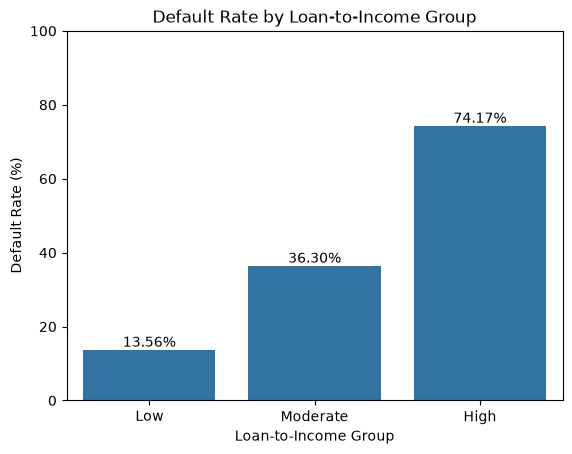

In [57]:
# Visualise the default rate across loan-to-income categories
default_rate = ld.groupby('loan_income_group', observed=True)['loan_status'].mean() * 100

sns.barplot(x=default_rate.index, y=default_rate.values)

plt.title('Default Rate by Loan-to-Income Group')
plt.xlabel('Loan-to-Income Group')
plt.ylabel('Default Rate (%)')
plt.ylim(0, 100)

# Display the percentage above each bar
for i, value in enumerate(default_rate.values):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()

Default rates increase considerably as the loan-to-income ratio rises. Borrowers in the high loan-to-income category have the highest default rate (74.17%), compared with 36.30% for the moderate category and 13.56% for the low category. This suggests that borrowers with higher loan burdens relative to their income may face greater difficulty meeting repayment obligations.

In [58]:
# Group borrowers according to their employment length
ld['employment_group'] = pd.cut(
    ld['person_emp_length'],
    bins=[-float('inf'), 2, 5, 10, float('inf')],
    labels=['2 years or less', '3-5 years', '6-10 years', 'Above 10 years']
)

In [59]:
# Count borrowers in each employment length category
ld['employment_group'].value_counts().sort_index()

employment_group
2 years or less    10814
3-5 years           9229
6-10 years          8564
Above 10 years      2915
Name: count, dtype: int64

In [60]:
# Compare default rates across the newly created employment groups
ld.groupby('employment_group', observed=True)['loan_status'].mean() * 100

employment_group
2 years or less    27.122249
3-5 years          20.056344
6-10 years         18.099019
Above 10 years     16.226415
Name: loan_status, dtype: float64

Default rates decrease as employment length increases. Borrowers with 2 years or less of employment have the highest default rate (27.12%), while those with more than 10 years have the lowest (16.23%). This suggests that shorter employment histories may be associated with higher loan default risk

## 9. Model Development

In [19]:
# Separate the target variable from the predictor variables
X = ld.drop(columns=['loan_status'])
y = ld['loan_status']

In [20]:
# Check the dimensions of the features and target
print("Features:", X.shape)
print("Target:", y.shape)

Features: (32581, 11)
Target: (32581,)


In [21]:
# Split the data into 70% training and 30% testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [29]:
# Check the dimensions of the training and testing sets
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (22806, 11)
X_test: (9775, 11)
y_train: (22806,)
y_test: (9775,)


In [22]:
# Compare the default and non-default proportions across both datasets
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
loan_status
0    78.185565
1    21.814435
Name: proportion, dtype: float64

Testing target distribution:
loan_status
0    78.179028
1    21.820972
Name: proportion, dtype: float64


The training and testing datasets maintain almost identical proportions of defaulters and non-defaulters. This confirms that stratified sampling was successful and ensures that both datasets adequately represent the original target distribution.

In [23]:
# Identify numerical and categorical predictor columns
numerical_features = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

Categorical features: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


C:\Users\HP\AppData\Local\Temp\ipykernel_18556\658817351.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()


In [24]:
# Handle missing numerical values and scale numerical features
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [25]:
# Handle missing categorical values and encode categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [26]:
# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [28]:
# Learn preprocessing parameters from training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned preprocessing steps to the test data
X_test_processed = preprocessor.transform(X_test)

In [29]:
# Check the dimensions of the preprocessed datasets
print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (22806, 26)
Processed testing data: (9775, 26)


The preprocessing pipeline successfully transformed both training and testing datasets into 37 numerical features. The increase from the original 14 features is due to One-Hot Encoding of categorical variables. The preprocessing parameters were learned from the training data and subsequently applied to the testing data to prevent data leakage.

In [30]:
# Import and initialise the Logistic Regression model
loan = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

In [31]:
# Train the Logistic Regression model
Loan_Default= loan.fit(X_train_processed, y_train)

In [32]:
# Generate predictions using the training data
y_train_pred = Loan_Default.predict(X_train_processed)

In [33]:
# Import classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate training performance metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_roc_auc = roc_auc_score(y_train, Loan_Default.predict_proba(X_train_processed)[:, 1])

print("TRAINING PERFORMANCE")
print("---------------------")
print("Accuracy:", train_accuracy)
print("Precision:", train_precision)
print("Recall:", train_recall)
print("F1-score:", train_f1)
print("ROC-AUC:", train_roc_auc)

TRAINING PERFORMANCE
---------------------
Accuracy: 0.809962290625274
Precision: 0.5454674421903816
Recall: 0.7728643216080402
F1-score: 0.6395542248835662
ROC-AUC: 0.8697761591311388


1. Recall (78.03%)

This is encouraging. The model identifies approximately 78 out of every 100 actual defaulters in the training data.

2. Precision (54.50%)

This is relatively modest. It means that some borrowers predicted to default actually wouldn't default.

3. ROC-AUC (87.20%)

This suggests that the model has good discriminatory ability.

In [39]:
# Generate training predictions using a 0.4 classification threshold
y_train_proba = Loan_Default.predict_proba(X_train_processed)[:, 1]

y_train_pred_04 = (y_train_proba >= 0.4).astype(int)

In [40]:
# Generate the training confusion matrix
train_cm = confusion_matrix(y_train, y_train_pred)

print(train_cm)

[[14627  3204]
 [ 1130  3845]]


The confusion matrix shows that the Logistic Regression model correctly identified 14,492 non-defaulters and 3,872 defaulters in the training dataset. However, it incorrectly classified 3,233 non-defaulters as defaulters and failed to identify 1,090 actual defaulters. This indicates that although the model identifies a considerable proportion of defaulters, there is still room for improvement in reducing incorrect predictions.

In [41]:
# Generate training predictions using a 0.6 classification threshold
y_train_pred_06 = (y_train_proba >= 0.6).astype(int)

In [48]:
# Calculate training performance using the 0.6 threshold
train_accuracy_06 = accuracy_score(y_train, y_train_pred_06)
train_precision_06 = precision_score(y_train, y_train_pred_06)
train_recall_06 = recall_score(y_train, y_train_pred_06)
train_f1_06 = f1_score(y_train, y_train_pred_06)

print("TRAINING PERFORMANCE - THRESHOLD 0.6")
print("------------------------------------")
print("Accuracy:", train_accuracy_06)
print("Precision:", train_precision_06)
print("Recall:", train_recall_06)
print("F1-score:", train_f1_06)

TRAINING PERFORMANCE - THRESHOLD 0.6
------------------------------------
Accuracy: 0.8461369814960975
Precision: 0.6288224956063269
Recall: 0.7191959798994975
F1-score: 0.6709798406000937


The classification threshold was adjusted to 0.4 and 0.6 to examine its effect on model performance. Although the 0.6 threshold produced higher accuracy, precision and F1-score, it reduced recall from 78.03% to 71.92%.

Considering the importance of identifying potential loan defaulters, the default threshold of 0.5 was retained as the baseline for subsequent model development and evaluation.

9.6.1 Setting Up Hyperparameter Tuning

In [42]:
# Import tools for hyperparameter tuning and cross-validation
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# Build a pipeline containing preprocessing and Logistic Regression
loan_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

# Define the parameter combinations to investigate
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': ['balanced', None]
}

# Set up stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Here, We're testing 10 different parameter combinations across 5 cross-validation folds to identify the combination with the best average F1-score

In [44]:
# Search for the best Logistic Regression hyperparameters
grid_search = GridSearchCV(
    estimator=loan_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit the search using training data only
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': ['balanced', None]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_pl

In [45]:
# Display the best Logistic Regression parameters and cross-validation score
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1-score:", grid_search.best_score_)

Best Parameters: {'model__C': 100, 'model__class_weight': None}
Best Cross-Validation F1-score: 0.6409722560646027


In [46]:
# Generate predictions using the tuned model on training data
Loan_Default_Tuned = grid_search.best_estimator_

y_train_tuned_pred = Loan_Default_Tuned.predict(X_train)

In [47]:
# Calculate training performance metrics for the tuned model
train_tuned_accuracy = accuracy_score(y_train, y_train_tuned_pred)
train_tuned_precision = precision_score(y_train, y_train_tuned_pred)
train_tuned_recall = recall_score(y_train, y_train_tuned_pred)
train_tuned_f1 = f1_score(y_train, y_train_tuned_pred)
train_tuned_roc_auc = roc_auc_score(
    y_train, Loan_Default_Tuned.predict_proba(X_train)[:, 1]
)

print("TUNED LOGISTIC REGRESSION - TRAINING PERFORMANCE")
print("------------------------------------------------")
print("Accuracy:", train_tuned_accuracy)
print("Precision:", train_tuned_precision)
print("Recall:", train_tuned_recall)
print("F1-score:", train_tuned_f1)
print("ROC-AUC:", train_tuned_roc_auc)

TUNED LOGISTIC REGRESSION - TRAINING PERFORMANCE
------------------------------------------------
Accuracy: 0.8663948083837587
Precision: 0.7668881506090809
Recall: 0.5567839195979899
F1-score: 0.6451612903225806
ROC-AUC: 0.8683698115951302


In [48]:
# Generate the confusion matrix for the tuned Logistic Regression model
train_tuned_cm = confusion_matrix(y_train, y_train_tuned_pred)

print(train_tuned_cm)

[[16989   842]
 [ 2205  2770]]


The confusion matrix shows that the tuned Logistic Regression model correctly identified 16,989 non-defaulters and 2,770 defaulters. However, it incorrectly classified 842 non-defaulters as defaulters and failed to identify 2,205 actual defaulters. This indicates that the tuned model reduced false positives but missed a considerable number of actual defaulters.

9.6.5 Evaluating the Tuned Model on Test Data

In [49]:
# Generate predictions using the tuned model on unseen test data
y_test_tuned_pred = Loan_Default_Tuned.predict(X_test)

In [50]:
# Evaluate the tuned model using test data
test_tuned_accuracy = accuracy_score(y_test, y_test_tuned_pred)
test_tuned_precision = precision_score(y_test, y_test_tuned_pred)
test_tuned_recall = recall_score(y_test, y_test_tuned_pred)
test_tuned_f1 = f1_score(y_test, y_test_tuned_pred)
test_tuned_roc_auc = roc_auc_score(
    y_test, Loan_Default_Tuned.predict_proba(X_test)[:, 1]
)

print("Test Accuracy:", test_tuned_accuracy)
print("Test Precision:", test_tuned_precision)
print("Test Recall:", test_tuned_recall)
print("Test F1-score:", test_tuned_f1)
print("Test ROC-AUC:", test_tuned_roc_auc)

Test Accuracy: 0.8697698209718671
Test Precision: 0.7731893265565438
Test Recall: 0.5705578996718237
Test F1-score: 0.6565956298893985
Test ROC-AUC: 0.8718533413871303


In [51]:
# Generate the test confusion matrix for the tuned model
test_tuned_cm = confusion_matrix(y_test, y_test_tuned_pred)
print(test_tuned_cm)

[[7285  357]
 [ 916 1217]]


The confusion matrix shows that the tuned Logistic Regression model correctly identified 7,285 non-defaulters and 1,217 defaulters. However, it incorrectly classified 357 non-defaulters as defaulters and failed to identify 916 actual defaulters. This indicates that although the model performs well in identifying non-defaulters, its ability to detect actual defaulters still needs improvement.

In [52]:
# Rebuild and train the original Logistic Regression pipeline
Loan_Default_Original = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

Loan_Default_Original.fit(X_train, y_train)

# Generate predictions on unseen test data
y_test_original_pred = Loan_Default_Original.predict(X_test)

In [61]:
# Calculate test performance metrics for the original model
test_original_accuracy = accuracy_score(y_test, y_test_original_pred)
test_original_precision = precision_score(y_test, y_test_original_pred)
test_original_recall = recall_score(y_test, y_test_original_pred)
test_original_f1 = f1_score(y_test, y_test_original_pred)
test_original_roc_auc = roc_auc_score(
    y_test, Loan_Default_Original.predict_proba(X_test)[:, 1]
)

print("Test Accuracy:", test_original_accuracy)
print("Test Precision:", test_original_precision)
print("Test Recall:", test_original_recall)
print("Test F1-score:", test_original_f1)
print("Test ROC-AUC:", test_original_roc_auc)

Test Accuracy: 0.8128900255754475
Test Precision: 0.5499671268902038
Test Recall: 0.784341303328645
Test F1-score: 0.6465700483091787
Test ROC-AUC: 0.8738421286465241


The comparison shows that hyperparameter tuning improved the model's accuracy, precision and F1-score. However, recall decreased from 78.43% to 57.06%, indicating that the tuned model missed more actual loan defaulters. The original model demonstrated stronger recall and a slightly higher ROC-AUC, while the tuned model was more precise in identifying potential defaulters. Therefore, both models offer different advantages, and further evaluation is necessary before selecting the final model.

In [53]:
# Generate the test confusion matrix for the original model
test_original_cm = confusion_matrix(y_test, y_test_original_pred)
print(test_original_cm)

[[6273 1369]
 [ 460 1673]]


The confusion matrix comparison shows that the original Logistic Regression model identified more actual defaulters (1,673) than the tuned model (1,217), while missing fewer defaulters (460 compared to 916). However, the original model also produced more false positives (1,369 compared to 357). The tuned model was more conservative in predicting defaults, resulting in fewer false alarms but a higher number of missed defaulters. This highlights the trade-off between recall and precision in credit risk prediction.

9.7 Random Forest Classifier

In [54]:
# Import and initialise the Random Forest model
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

In [55]:
# Train the Random Forest model using training data
Loan_Default_RF = rf_pipeline.fit(X_train, y_train)

In [56]:
# Generate predictions on the training data
y_train_rf_pred = Loan_Default_RF.predict(X_train)

# Calculate training performance metrics
train_rf_accuracy = accuracy_score(y_train, y_train_rf_pred)
train_rf_precision = precision_score(y_train, y_train_rf_pred)
train_rf_recall = recall_score(y_train, y_train_rf_pred)
train_rf_f1 = f1_score(y_train, y_train_rf_pred)
train_rf_roc_auc = roc_auc_score(
    y_train, Loan_Default_RF.predict_proba(X_train)[:, 1]
)

print("Training Accuracy:", train_rf_accuracy)
print("Training Precision:", train_rf_precision)
print("Training Recall:", train_rf_recall)
print("Training F1-score:", train_rf_f1)
print("Training ROC-AUC:", train_rf_roc_auc)

Training Accuracy: 0.9997369113391212
Training Precision: 0.9987954226059025
Training Recall: 1.0
Training F1-score: 0.9993973483326637
Training ROC-AUC: 1.0


In [57]:
# Generate predictions on unseen test data
y_test_rf_pred = Loan_Default_RF.predict(X_test)

In [58]:
# Calculate test performance metrics for the Random Forest model
test_rf_accuracy = accuracy_score(y_test, y_test_rf_pred)
test_rf_precision = precision_score(y_test, y_test_rf_pred)
test_rf_recall = recall_score(y_test, y_test_rf_pred)
test_rf_f1 = f1_score(y_test, y_test_rf_pred)
test_rf_roc_auc = roc_auc_score(
    y_test, Loan_Default_RF.predict_proba(X_test)[:, 1]
)

print("Test Accuracy:", test_rf_accuracy)
print("Test Precision:", test_rf_precision)
print("Test Recall:", test_rf_recall)
print("Test F1-score:", test_rf_f1)
print("Test ROC-AUC:", test_rf_roc_auc)

Test Accuracy: 0.9264450127877237
Test Precision: 0.8994350282485876
Test Recall: 0.7463666197843413
Test F1-score: 0.8157827312323853
Test ROC-AUC: 0.9355259439868479


The Random Forest model achieved strong performance on the test dataset, with an accuracy of 92.64%, precision of 89.94%, recall of 74.64%, F1-score of 81.58% and ROC-AUC of 93.55%. Although its training performance was almost perfect, the lower test scores suggest some degree of overfitting. Nevertheless, the model demonstrated better overall test performance than both Logistic Regression models, particularly in precision, F1-score and ROC-AUC.

In [59]:
# Generate the test confusion matrix for Random Forest
test_rf_cm = confusion_matrix(y_test, y_test_rf_pred)
print(test_rf_cm)

[[7464  178]
 [ 541 1592]]


The confusion matrix shows that the Random Forest model correctly identified 7,464 non-defaulters and 1,592 defaulters. It incorrectly classified 178 non-defaulters as defaulters and failed to identify 541 actual defaulters. The relatively low number of false positives and strong identification of actual defaulters demonstrate the model's promising performance in predicting loan defaults.

9.8 Model Comparison

In [60]:
# Compare the test performance of all three models
model_comparison = pd.DataFrame({
    'Model': ['Original Logistic Regression', 'Tuned Logistic Regression', 'Random Forest'],
    'Accuracy': [0.8129, 0.8698, 0.9264],
    'Precision': [0.5500, 0.7732, 0.8994],
    'Recall': [0.7843, 0.5706, 0.7464],
    'F1-score': [0.6466, 0.6566, 0.8158],
    'ROC-AUC': [0.8738, 0.8719, 0.9355]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Original Logistic Regression,0.8129,0.5500,0.7843,0.6466,0.8738
1,Tuned Logistic Regression,0.8698,0.7732,0.5706,0.6566,0.8719
2,Random Forest,0.9264,0.8994,0.7464,0.8158,0.9355


The Random Forest model demonstrated the strongest overall performance on the test dataset, achieving the highest accuracy, precision, F1-score and ROC-AUC. However, the original Logistic Regression recorded the highest recall, meaning it identified a larger proportion of actual loan defaulters. This highlights a trade-off between identifying more defaulters and reducing false alarms. Overall, Random Forest is currently the strongest model, although further improvements in recall may be beneficial.

10. Model Improvement

In [61]:
# Obtain default probabilities from the Random Forest model
y_test_rf_prob = Loan_Default_RF.predict_proba(X_test)[:, 1]

In [62]:
# Classify borrowers using a threshold of 0.4
y_test_rf_04 = (y_test_rf_prob >= 0.4).astype(int)

In [63]:
# Evaluate Random Forest performance at the 0.4 threshold
print("Accuracy:", accuracy_score(y_test, y_test_rf_04))
print("Precision:", precision_score(y_test, y_test_rf_04))
print("Recall:", recall_score(y_test, y_test_rf_04))
print("F1-score:", f1_score(y_test, y_test_rf_04))

# Display the confusion matrix
confusion_matrix(y_test, y_test_rf_04)

Accuracy: 0.9081329923273658
Precision: 0.792238523426408
Recall: 0.7848101265822784
F1-score: 0.7885068299576071


array([[7203,  439],
       [ 459, 1674]])

Reducing the classification threshold from 0.5 to 0.4 improved the Random Forest model's recall from 74.64% to 78.48%, allowing it to identify more actual loan defaulters. However, precision decreased from 89.94% to 79.22%, while accuracy also declined slightly. This indicates a trade-off between identifying more potential defaulters and minimising false positive predictions.

11. Findings and Recommendations

#11.1 Key Findings

The analysis of the loan dataset revealed several factors associated with loan default:

1. **Loan Grade:** Borrowers with lower loan grades recorded substantially higher default rates. Grade G had the highest default rate at 98.44%, while Grade A had the lowest at 9.96%.

2. **Home Ownership:** Borrowers living in rented accommodation had a higher default rate (31.57%) than those who owned their homes (7.47%).

3. **Previous Default History:** Borrowers with a previous default record had a default rate of 37.81%, compared with 18.39% among those without a recorded previous default.

4. **Loan-to-Income Ratio:** Borrowers with higher loan-to-income ratios were considerably more likely to default. The high-ratio group recorded a default rate of 74.17%.

5. **Interest Rate:** Borrowers who defaulted had a higher average interest rate (13.06%) than non-defaulters (10.44%).

6. **Employment Length:** Borrowers with shorter employment histories generally recorded higher default rates.

7. **Model Performance:** Random Forest achieved the strongest overall test performance, with an F1-score of 81.58% and ROC-AUC of 93.55% at the default threshold of 0.5. Lowering the threshold to 0.4 increased recall to 78.48%, although precision declined.

#11.2 Recommendations

1. **Strengthen Credit Assessment:** Financial institutions should carefully assess borrowers' credit grades and previous default history before approving loans.

2. **Monitor Loan-to-Income Ratios:** Lenders should evaluate borrowers' existing financial commitments and income to ensure that loan repayments remain affordable.

3. **Consider Employment Stability:** Employment length should be considered during credit assessment, as borrowers with shorter employment histories showed higher default rates.

4. **Apply Risk-Based Interest Rates:** Interest rates should reflect borrowers' credit risk while remaining affordable to reduce the possibility of repayment difficulties.

5. **Use Predictive Models:** Financial institutions can adopt machine learning models such as Random Forest to support loan risk assessment and identify potentially high-risk applications.

6. **Optimise Classification Thresholds:** Lenders should select classification thresholds based on their risk tolerance. A lower threshold may help identify more potential defaulters, but could also increase false alarms.

#12.3 Conclusion

This project examined the factors influencing loan defaults and developed machine learning models to predict borrowers' likelihood of defaulting on loans.

The exploratory data analysis revealed that loan grade, home ownership, previous default history, loan-to-income ratio, interest rate and employment length were among the factors associated with loan default.

Three classification models were developed and evaluated: Original Logistic Regression, Tuned Logistic Regression and Random Forest. Random Forest demonstrated the strongest overall performance, achieving 92.64% accuracy, 89.94% precision, 74.64% recall and an F1-score of 81.58% on the test dataset.

Further experimentation with classification thresholds showed that reducing the threshold to 0.4 improved recall to 78.48%, allowing the model to identify more actual defaulters.

Overall, the project demonstrates how data analysis and machine learning can support credit risk assessment, improve lending decisions and help financial institutions identify borrowers who may be at a higher risk of default. However, model predictions should support, rather than completely replace, human judgement in credit decisions.

12. References and Materials Used

In [ ]:
### References and Materials Used

The following resources were consulted during the development of this project:

1. **Scikit-learn Documentation:** Classification Threshold Tuning.
2. **Scikit-learn Documentation:** Precision-Recall Curve.
3. **CGAP:** Credit Scoring Technical Guide (2019).
4. **Research Paper:** Machine Learning for Default Prediction (2023).
5. **Research Paper:** Loan Default Prediction and SMOTE (2025).

### Python Libraries Used

- Pandas – Data manipulation and analysis.
- NumPy – Numerical computations.
- Matplotlib – Data visualisation.
- Seaborn – Statistical data visualisation.
- Scikit-learn – Data preprocessing, model development, hyperparameter tuning and evaluation.


**Dataset Source**

The dataset used for this project was obtained from Kaggle:

Lao Tse. *Credit Risk Dataset*. Kaggle.

https://www.kaggle.com/datasets/laotse/credit-risk-dataset